# 🍎 Chuva de maçãs: um DQN que aprende olhando a tela

Na Q-table, cada casa do labirinto era uma linha da tabela. Aqui o agente recebe **a tela do jogo**, como no Atari: pixels. Não há tabela que caiba. É o caminho dos **slides 118 a 125**, numa versão pequena que treina em cerca de 2 minutos.

**O jogo:** maçãs caem do céu **na diagonal** e quicam nas paredes. Você controla a cesta (⬅️ ⏸️ ➡️).

| Acontece | Recompensa |
|---|---|
| 🍎 a maçã cai na cesta | **+1** |
| 💥 a maçã cai no chão | **−1** |

**O detalhe que torna o jogo interessante:** a maçã anda **até 2 casas** para o lado a cada passo; a cesta, só **1**. Não adianta correr atrás da maçã: é preciso **prever onde ela vai cair**.

### O que você vai fazer (≈ 45 min, dos quais cerca de 7 são treino)

| Seção | Você... | Slide |
|---|---|---|
| 1 | 🎮 **joga** o jogo com os botões | — |
| 2 | 🖼️ prepara a tela: cinza, menor, 4 frames | 120 |
| 3 | 🕵️ **é a rede**: adivinha para onde a maçã vai com 1 frame e com 4 | 120 |
| 4 | 🧠 monta a rede: enxergar → combinar → pontuar | 121 |
| 5 | 📒🎯 dá a ela memória (replay) e gabarito (rede-alvo) | 122–124 |
| 6 | ⏱️ treina (≈ 2 min) e lê a curva | 131 |
| 7 | 🎬 assiste ao agente sem treino × treinado, com os Q ao vivo | 121 |
| 8 | 🔍 espia o que a rede **enxerga** por dentro | 121 |
| 9 | 🏁 avalia direito: contra o acaso e contra uma regra esperta | 131 |
| 10 | 🎯 **Desafio:** e se a rede visse só 1 frame? | 120 |
| 11 | 🎯 **Mão na massa:** tira o replay, tira a rede-alvo. Qual faz mais falta? | 123–125 |

> **Como usar:** rode as células em ordem (Shift + Enter). Sempre que aparecer **🤔 Palpite**, a dupla escreve a aposta **antes** de rodar. Depois, confira no **🔎 O que observar**. Onde aparecer 👈, troque o valor e rode de novo.

In [1]:
import copy
import time
import random
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import torch
import torch.nn as nn

torch.manual_seed(0); random.seed(0); np.random.seed(0)
br = lambda x, d=2: f'{x:.{d}f}'.replace('.', ',')   # número no formato brasileiro
print(f'PyTorch {torch.__version__}. Não precisa de GPU: a rede é pequena.')

PyTorch 2.6.0+cu126. Não precisa de GPU: a rede é pequena.


---
## 1. 🎮 O jogo: primeiro, jogue você

O mundo é uma grade **12 × 12**. A tela que o jogo desenha tem **36 × 36 pixels coloridos** (cada casa vira um quadradinho de 3 × 3 pixels): céu azul, maçã vermelha com folhinha verde, cesta marrom.

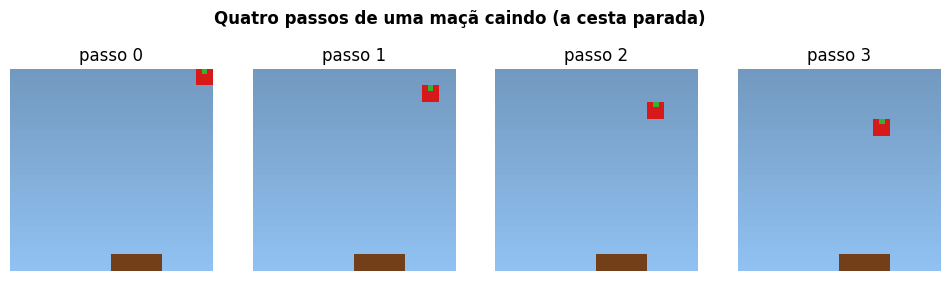

In [2]:
L, P = 12, 3          # grade 12 × 12; cada casa vira 3 × 3 pixels
ESQ, FICA, DIR = 0, 1, 2
ACOES = ['⬅️', '⏸️', '➡️']


class ChuvaDeMacas:
    '''A maçã cai uma linha por passo, andando vx casas para o lado (|vx| = 1 ou 2) e quicando nas paredes.'''

    def __init__(self, seed=None):
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.ax, self.ay = int(self.rng.integers(L)), 0                 # maçã: coluna sorteada, no topo
        self.vx = int(self.rng.choice([-2, -1, 1, 2]))                  # velocidade lateral (escondida!)
        self.cx = int(self.rng.integers(1, L - 1))                      # centro da cesta (3 casas)
        return self

    def passo(self, acao):
        '''Move a cesta e a maçã. Devolve (recompensa, terminou).'''
        self.cx = int(np.clip(self.cx + (acao - 1), 1, L - 2))
        x = self.ax + self.vx
        if x < 0:                                                        # quica na parede da esquerda
            x, self.vx = -x, -self.vx
        if x > L - 1:                                                    # quica na parede da direita
            x, self.vx = 2 * (L - 1) - x, -self.vx
        self.ax, self.ay = x, self.ay + 1
        if self.ay == L - 1:                                             # chegou ao chão
            return (1.0 if abs(self.ax - self.cx) <= 1 else -1.0), True
        return 0.0, False

    def tela(self):
        '''A TELA do jogo: imagem colorida 36 × 36 × 3 (é isso que um humano veria).'''
        img = np.zeros((L * P, L * P, 3))
        img[:] = np.linspace(0.75, 0.95, L * P)[:, None, None] * np.array([0.6, 0.8, 1.0])   # céu
        y, x = self.ay * P, self.ax * P
        img[y:y + P, x:x + P] = [0.85, 0.1, 0.1]                                             # maçã
        img[y, x + 1] = [0.2, 0.7, 0.2]                                                      # folhinha
        yb = (L - 1) * P
        img[yb:yb + P, (self.cx - 1) * P:(self.cx + 2) * P] = [0.45, 0.25, 0.1]              # cesta
        return img


jogo = ChuvaDeMacas(seed=7).reset()
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for k, ax in enumerate(axes):
    ax.imshow(jogo.tela()); ax.set_title(f'passo {k}'); ax.axis('off')
    jogo.passo(FICA)
fig.suptitle('Quatro passos de uma maçã caindo (a cesta parada)', fontweight='bold')
plt.show()

### 🎮 Sua vez: pegue 5 maçãs

Use os botões. Cada clique é **um passo** do jogo. Dica: observe a maçã por dois ou três passos **antes** de decidir para onde ir.

> Se os botões não aparecerem (fora do Colab), pule esta célula: ela não é necessária para o resto.

In [3]:
# @title 🎮 Jogar (rode e use os botões)
import ipywidgets as widgets


def jogar_voce(n_macas=5, seed=None):
    jogo = ChuvaDeMacas(seed).reset()
    estado = {'pegou': 0, 'jogadas': 0, 'esperando': False}
    tela_out, texto = widgets.Output(), widgets.HTML()

    def desenhar(msg=''):
        with tela_out:
            tela_out.clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(3.3, 3.3))
            ax.imshow(jogo.tela()); ax.axis('off')
            plt.show()
        texto.value = (f"<b>Maçã {min(estado['jogadas'] + 1, n_macas)} de {n_macas}</b> · "
                       f"pegou {estado['pegou']} · {msg}")

    def agir(acao):
        if estado['jogadas'] >= n_macas:
            return
        if estado['esperando']:                      # o clique seguinte começa a próxima maçã
            estado['esperando'] = False
            jogo.reset(); desenhar('nova maçã!')
            return
        r, fim = jogo.passo(acao)
        if not fim:
            desenhar(); return
        estado['jogadas'] += 1
        estado['pegou'] += r > 0
        if estado['jogadas'] == n_macas:
            desenhar(f"🏁 <b>Fim: {estado['pegou']} de {n_macas}</b>. Guarde esse número!")
        else:
            estado['esperando'] = True
            desenhar(('🍎 <b>Pegou! +1</b>' if r > 0 else '💥 <b>Caiu no chão: −1</b>') + ' (clique para a próxima)')

    botoes = [widgets.Button(description=d, layout=widgets.Layout(width='70px')) for d in ACOES]
    for b, a in zip(botoes, (ESQ, FICA, DIR)):
        b.on_click(lambda _, a=a: agir(a))
    display(widgets.VBox([texto, tela_out, widgets.HBox(botoes)]))
    desenhar('comece!')


jogar_voce()

**🔎 O que observar:** você provavelmente esperou um ou dois passos para ver **para que lado** a maçã ia. Seu cérebro comparou imagens seguidas. Guarde essa ideia: a rede vai precisar fazer o mesmo.

---
## 2. 🖼️ Preparando a tela (slide 120)

**Objetivo:** entregar à rede só o que importa para decidir, com menos custo de treino.

| Etapa | O que faz | Por quê |
|---|---|---|
| 1 · **Cinza** | 3 canais (RGB) → 1 | a cor não muda a decisão; a forma, sim |
| 2 · **Reduzir** | 36 × 36 → 12 × 12 | menos pixels, treino mais barato |
| 3 · **Empilhar 4 frames** | 1 foto → 1 "vídeo curto" | 1 frame mostra **onde** a maçã está; 4 mostram **para onde vai** |

> 🤔 **Palpite:** quantos números a tela colorida tem? E quantos sobram depois das 3 etapas?

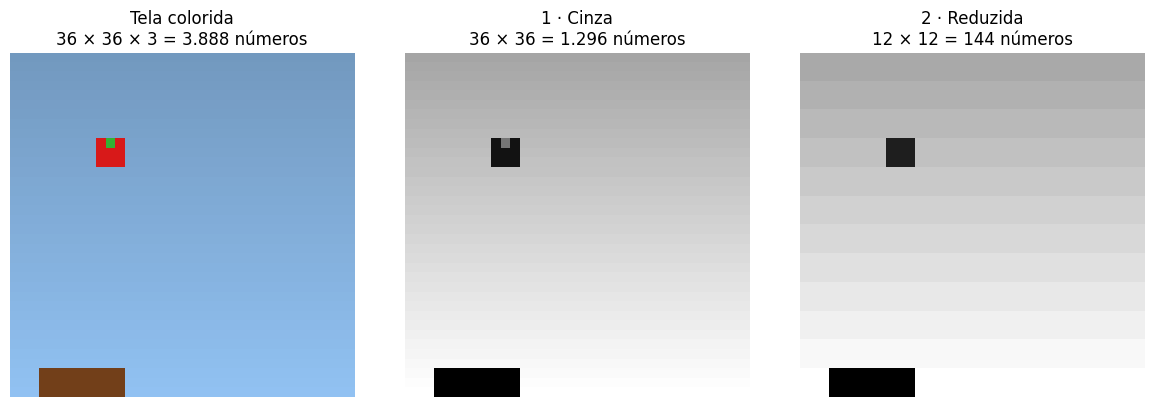

Com a pilha de 4 frames, a rede recebe 4 × 144 = 576 números, 6,8 vezes menos que uma única tela colorida.


In [4]:
# ======================================================================
# 📚 NA AULA · PREPARANDO A TELA (slide 120): cinza → reduzir → empilhar 4 frames
# ======================================================================
N_FRAMES = 4


def preparar(img):
    '''Etapas 1 e 2: tela colorida 36 × 36 × 3 → cinza → 12 × 12.'''
    cinza = img @ np.array([0.299, 0.587, 0.114])                 # 1 · cinza (média ponderada dos canais)
    return cinza.reshape(L, P, L, P).mean(axis=(1, 3)).astype(np.float32)   # 2 · reduzir (média de cada 3 × 3)


class Pilha:
    '''Etapa 3: guarda os últimos N frames preparados. É o ESTADO que a rede recebe.'''

    def __init__(self, n=N_FRAMES):
        self.frames = deque(maxlen=n)

    def reiniciar(self, frame):
        for _ in range(self.frames.maxlen):
            self.frames.append(frame)                          # no início, repete o primeiro frame
        return self.estado()

    def adicionar(self, frame):
        self.frames.append(frame)                              # o mais antigo sai sozinho
        return self.estado()

    def estado(self):
        return np.stack(self.frames)                           # forma: (N_FRAMES, 12, 12)


jogo = ChuvaDeMacas(seed=3).reset()
for _ in range(3):
    jogo.passo(FICA)
img = jogo.tela()
cinza = img @ np.array([0.299, 0.587, 0.114])
pequena = preparar(img)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img); axes[0].set_title(f'Tela colorida\n36 × 36 × 3 = {img.size:,} números'.replace(',', '.'))
axes[1].imshow(cinza, cmap='gray'); axes[1].set_title(f'1 · Cinza\n36 × 36 = {cinza.size:,} números'.replace(',', '.'))
axes[2].imshow(pequena, cmap='gray'); axes[2].set_title(f'2 · Reduzida\n12 × 12 = {pequena.size} números')
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.show()
print(f'Com a pilha de {N_FRAMES} frames, a rede recebe {N_FRAMES} × 144 = {N_FRAMES * 144} números, '
      f'{br(img.size / (N_FRAMES * 144), 1)} vezes menos que uma única tela colorida.')

**🔎 O que observar:** mesmo em 12 × 12 e em cinza, dá para ver a maçã (um quadradinho mais escuro) e a cesta (a barra no chão). A informação que importa para decidir **sobreviveu**; o resto foi embora.

---
## 3. 🕵️ Você é a rede (slide 120: "1 frame = foto, 4 frames = vídeo")

Abaixo está **exatamente** o que uma rede com 1 frame receberia.

> 🤔 **Palpite:** a maçã vai cair à **esquerda** ou à **direita** de onde está agora? Escreva antes de abrir a resposta.

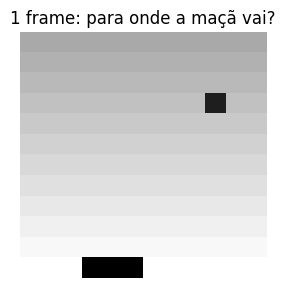

In [5]:
jogo = ChuvaDeMacas(seed=21).reset()
pilha = Pilha(4)
pilha.reiniciar(preparar(jogo.tela()))
for _ in range(3):
    jogo.passo(FICA)
    estado = pilha.adicionar(preparar(jogo.tela()))

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(estado[-1], cmap='gray'); ax.set_title('1 frame: para onde a maçã vai?'); ax.axis('off')
plt.show()

<details>
<summary><b>Ver resposta</b></summary>

Não dá para saber! Uma foto mostra **onde** a maçã está, mas não **para onde vai**. A mesma imagem poderia vir de uma maçã indo para a esquerda ou para a direita, devagar ou rápido. Rode a próxima célula para ver o "vídeo".
</details>

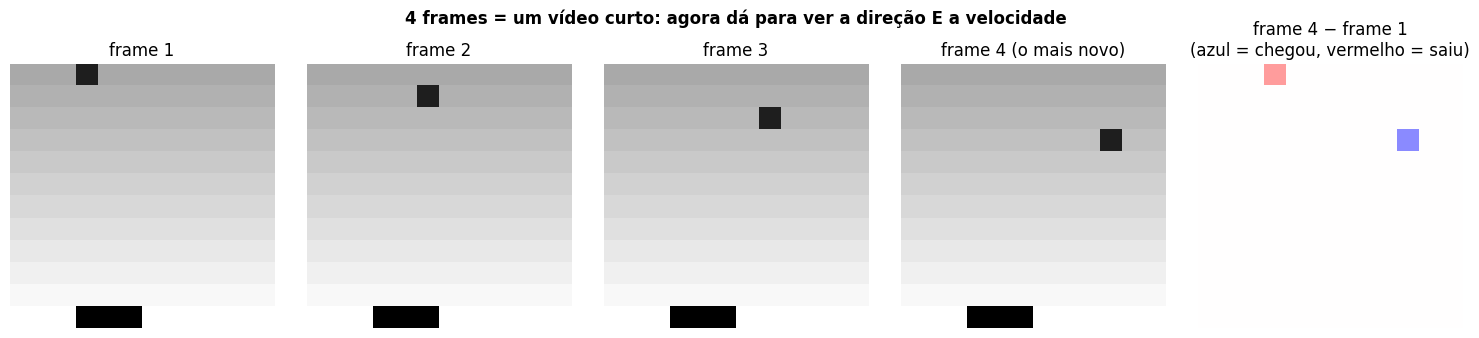

Resposta: vx = +2 (a maçã anda 2 casa(s) por passo para a direita).


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for k in range(4):
    axes[k].imshow(estado[k], cmap='gray'); axes[k].set_title(f'frame {k + 1}' + (' (o mais novo)' if k == 3 else ''))
movimento = estado[-1] - estado[0]
axes[4].imshow(movimento, cmap='bwr', vmin=-0.6, vmax=0.6)
axes[4].set_title('frame 4 − frame 1\n(azul = chegou, vermelho = saiu)')
for ax in axes:
    ax.axis('off')
fig.suptitle('4 frames = um vídeo curto: agora dá para ver a direção E a velocidade', fontweight='bold')
plt.tight_layout(); plt.show()
print(f'Resposta: vx = {jogo.vx:+d} (a maçã anda {abs(jogo.vx)} casa(s) por passo para a '
      f'{"direita" if jogo.vx > 0 else "esquerda"}).')

**🔎 O que observar:** com 4 frames, o rastro da maçã mostra a **direção** e a **velocidade**: o movimento virou parte do estado. A cesta (parada) aparece igual nos 4 frames, então some na diferença.

**Ponte com a propriedade de Markov (slide 30):** com 1 frame, o estado **não** carrega tudo o que importa do passado: falta a velocidade. A pilha de frames é o jeito de deixar o estado "Markov de novo".

---
## 4. 🧠 A rede: enxergar → combinar → pontuar (slide 121)

| Etapa | Camadas | Papel |
|---|---|---|
| 1 · **Enxergar** | 2 convoluções | detectam a maçã, a cesta e o movimento |
| 2 · **Combinar** | 1 camada densa | junta tudo o que foi visto |
| 3 · **Pontuar** | saída com 3 neurônios | um Q por ação: Q(⬅️), Q(⏸️), Q(➡️) |

A decisão é a de sempre: **a ação de maior Q** (slide 119: "mesma conta, outra memória").

In [7]:
# ======================================================================
# 📚 NA AULA · A ARQUITETURA (slide 121): tela (4 frames) → convoluções → densa → um Q por ação
# ======================================================================
class RedeQ(nn.Module):
    def __init__(self, n_frames=N_FRAMES, n_acoes=3):
        super().__init__()
        self.enxergar = nn.Sequential(                                       # 1 · convoluções
            nn.Conv2d(n_frames, 16, kernel_size=3, padding=1), nn.ReLU(),     # 16 "detectores" 12 × 12
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), nn.ReLU()  # 32 detectores 6 × 6
        )
        self.combinar = nn.Sequential(nn.Flatten(), nn.Linear(32 * 6 * 6, 128), nn.ReLU())   # 2 · densa
        self.pontuar = nn.Linear(128, n_acoes)                                # 3 · um Q por ação

    def forward(self, x):
        return self.pontuar(self.combinar(self.enxergar(x)))


rede = RedeQ()
n_params = sum(p.numel() for p in rede.parameters())
q = rede(torch.from_numpy(estado)[None])[0].detach().numpy()
print(f'Parâmetros da rede: {n_params:,}'.replace(',', '.'))
print('Q da rede SEM treino para a pilha acima:', '   '.join(f'Q({a}) = {br(v, 3)}' for a, v in zip(ACOES, q)))
print(f'Ação escolhida: {ACOES[int(np.argmax(q))]} (por enquanto, puro acaso)')

estados_reais = L * L * 4 * (L - 2)
print('\nE uma Q-table? Se o agente soubesse a posição exata da maçã, a velocidade e a cesta: '
      + f'{estados_reais:,} linhas.'.replace(',', '.'))
print(f'Mas ele só vê pixels. Pilhas de 576 pixels com 256 tons de cinza: 256^576 linhas possíveis (slide 118).')

Parâmetros da rede: 153.203
Q da rede SEM treino para a pilha acima: Q(⬅️) = 0,092   Q(⏸️) = -0,059   Q(➡️) = -0,077
Ação escolhida: ⬅️ (por enquanto, puro acaso)

E uma Q-table? Se o agente soubesse a posição exata da maçã, a velocidade e a cesta: 5.760 linhas.
Mas ele só vê pixels. Pilhas de 576 pixels com 256 tons de cinza: 256^576 linhas possíveis (slide 118).


**🔎 O que observar:** a rede sem treino dá Q's quase iguais, perto de zero: ela ainda não sabe nada. E repare na conta da Q-table: **ver pixels** é o que torna a tabela impossível, porque cada combinação de pixels seria uma linha.

> **Pergunta do slide 121:** se o jogo ganhasse a ação PULAR, o que mudaria na rede? (Dica: olhe o `n_acoes`.)

---
## 5. 📒 Memória e 🎯 gabarito (slides 122 a 124)

As duas outras ideias do DQN (slide 125), numa versão enxuta. Na seção 11 você vai tirar cada uma e ver o que acontece.

- **📒 Experience Replay:** cada jogada vira uma linha no caderno `(s, a, r, s′, fim)`. O treino sorteia **lotes** do caderno inteiro, não só a última jogada.
- **🎯 Rede-alvo:** uma cópia congelada da rede calcula o alvo $r + \gamma \cdot \max_{a'} Q_{\text{alvo}}(s',a')$. A cada C passos, ela recebe os pesos novos.

In [8]:
# ======================================================================
# 📚 NA AULA · EXPERIENCE REPLAY (slides 122–123) e REDE-ALVO (slide 124)
# ======================================================================
class Caderno:
    '''Replay buffer: guarda as últimas `capacidade` jogadas e sorteia lotes.'''

    def __init__(self, capacidade=20_000):
        self.linhas = deque(maxlen=capacidade)          # cheio? apaga a linha mais antiga

    def anotar(self, s, a, r, s2, fim):
        self.linhas.append((s, a, r, s2, fim))

    def sortear(self, n=64):
        lote = random.sample(self.linhas, min(n, len(self.linhas)))   # caderno pequeno: usa o que tiver
        s, a, r, s2, fim = zip(*lote)
        return (torch.from_numpy(np.stack(s)), torch.tensor(a), torch.tensor(r, dtype=torch.float32),
                torch.from_numpy(np.stack(s2)), torch.tensor(fim, dtype=torch.float32))


def passo_de_treino(rede, rede_alvo, otimizador, caderno, gamma=0.95):
    '''A conta do Q-Learning, num lote sorteado, com o alvo vindo da rede-alvo (slide 124).'''
    s, a, r, s2, fim = caderno.sortear()
    q_previsto = rede(s).gather(1, a[:, None]).squeeze(1)                     # ② previsão: Q(s, a)
    with torch.no_grad():
        alvo = r + gamma * rede_alvo(s2).max(1)[0] * (1 - fim)                # ① alvo (no fim: sem futuro)
    perda = nn.functional.smooth_l1_loss(q_previsto, alvo)                   # ③ erro
    otimizador.zero_grad(); perda.backward(); otimizador.step()               # ajusta os pesos
    return perda.item()

### A conta é a mesma da cobrinha (slides 119 e 124)

A rede-alvo calcula o alvo, a rede principal "chuta" o Q, e o erro mede a distância entre os dois. São os números do slide 124:

In [9]:
r, gamma, melhor_q_vizinho = -1.0, 0.9, 10.0      # a cena da cobrinha
alvo = r + gamma * melhor_q_vizinho              # ① a rede-alvo calcula o alvo
previsao = 3.5                                   # ② a rede principal chuta Q(Vazio 1, ↑)
erro = (alvo - previsao) ** 2                    # ③ quanto errou
print(f'① alvo = {br(r, 0)} + {br(gamma, 1)} × {br(melhor_q_vizinho, 0)} = {br(alvo, 0)}')
print(f'② previsão da rede = {br(previsao, 1)}')
print(f'③ erro = ({br(alvo, 0)} − {br(previsao, 1)})² = {br(erro)}')
print('\nNa tabela, escreveríamos 8 direto na célula. Na rede, o gradiente ajusta os 153 mil pesos para a previsão chegar perto de 8.')

① alvo = -1 + 0,9 × 10 = 8
② previsão da rede = 3,5
③ erro = (8 − 3,5)² = 20,25

Na tabela, escreveríamos 8 direto na célula. Na rede, o gradiente ajusta os 153 mil pesos para a previsão chegar perto de 8.


> **Detalhe técnico:** no treino usamos a perda **Huber** (`smooth_l1_loss`). Para erros pequenos, ela é igual ao quadrado do slide; para erros grandes, cresce mais devagar e deixa o treino mais estável.

---
## 6. ⏱️ Treinar (cerca de 2 minutos)

O agente joga **2.000 maçãs**. O ε começa em 1 (100% ao acaso) e cai até 0,05 na metade do treino. Guardamos "fotos" da rede em alguns momentos para comparar depois.

> 🤔 **Palpite:** depois de 2.000 maçãs, em quantos % delas o agente vai acertar? Mais ou menos que você na seção 1?

In [10]:
def treinar(n_frames=N_FRAMES, n_macas=2000, seed=0, C=500, capacidade=20_000, mostrar=True):
    '''Treina o DQN. C = a cada quantos passos a rede-alvo é atualizada; capacidade = tamanho do caderno.'''
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    jogo, pilha = ChuvaDeMacas(seed), Pilha(n_frames)
    rede = RedeQ(n_frames)
    rede_alvo = copy.deepcopy(rede)                                   # 🎯 a cópia congelada
    otimizador = torch.optim.Adam(rede.parameters(), lr=1e-3)
    caderno = Caderno(capacidade)
    passos, acertos, fotos = 0, [], {0: copy.deepcopy(rede)}
    total = n_macas * (L - 1)
    inicio = time.time()
    for n in range(1, n_macas + 1):
        s = pilha.reiniciar(preparar(jogo.reset().tela()))
        while True:
            eps = max(0.05, 1 - passos / (0.5 * total))                # ε cai até 0,05 na metade do treino
            if random.random() < eps:
                a = random.randrange(3)                                # explora
            else:
                with torch.no_grad():
                    a = int(rede(torch.from_numpy(s)[None]).argmax())  # explota: maior Q
            r, fim = jogo.passo(a)
            s2 = pilha.adicionar(preparar(jogo.tela()))
            caderno.anotar(s, a, r, s2, fim)                           # 📒 anota no caderno
            s = s2
            passos += 1
            if len(caderno.linhas) >= min(500, capacidade):
                passo_de_treino(rede, rede_alvo, otimizador, caderno)  # estuda um lote sorteado
            if passos % C == 0:
                rede_alvo.load_state_dict(rede.state_dict())           # 🎯 atualiza o gabarito
            if fim:
                acertos.append(int(r > 0))
                break
        if n in (300, 800):
            fotos[n] = copy.deepcopy(rede)
        if mostrar and n % 250 == 0:
            print(f'maçã {n:5d} · ε = {br(eps)} · acertos nas últimas 250: {np.mean(acertos[-250:]):4.0%} '
                  f'· {time.time() - inicio:4.0f} s')
    fotos[n_macas] = rede
    return rede, acertos, fotos


rede, acertos, fotos = treinar()

maçã   250 · ε = 0,75 · acertos nas últimas 250:  28% ·    9 s


maçã   500 · ε = 0,50 · acertos nas últimas 250:  24% ·   19 s


maçã   750 · ε = 0,25 · acertos nas últimas 250:  35% ·   29 s


maçã  1000 · ε = 0,05 · acertos nas últimas 250:  54% ·   39 s


maçã  1250 · ε = 0,05 · acertos nas últimas 250:  71% ·   50 s


maçã  1500 · ε = 0,05 · acertos nas últimas 250:  89% ·   60 s


maçã  1750 · ε = 0,05 · acertos nas últimas 250:  97% ·   71 s


maçã  2000 · ε = 0,05 · acertos nas últimas 250:  96% ·   82 s


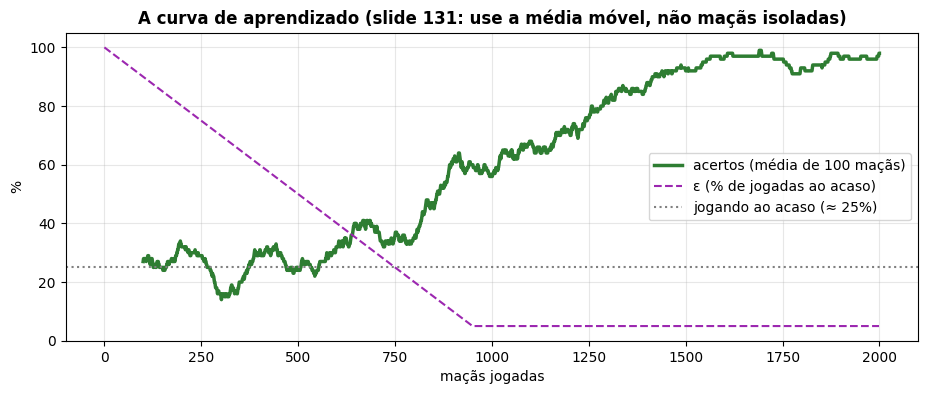

In [11]:
janela = 100
media = np.convolve(acertos, np.ones(janela) / janela, mode='valid')
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(janela, len(acertos) + 1), media * 100, color='#2E7D32', lw=2.5, label=f'acertos (média de {janela} maçãs)')
eps = [max(0.05, 1 - k * (L - 1) / (0.5 * len(acertos) * (L - 1))) for k in range(len(acertos))]
ax.plot(np.array(eps) * 100, '--', color='#9C27B0', label='ε (% de jogadas ao acaso)')
ax.axhline(25, color='gray', ls=':', label='jogando ao acaso (≈ 25%)')
ax.set_xlabel('maçãs jogadas'); ax.set_ylabel('%'); ax.set_ylim(0, 105); ax.grid(alpha=0.3); ax.legend()
ax.set_title('A curva de aprendizado (slide 131: use a média móvel, não maçãs isoladas)', fontweight='bold')
plt.show()

**🔎 O que observar**
- **No começo,** o agente acerta perto de 25%: é o acaso (a cesta cobre 3 das 12 colunas).
- **Os acertos disparam por volta da maçã 750** e **continuam subindo depois que o ε para de cair** (perto da maçã 950). Essa segunda parte da subida é a rede aprendendo de verdade, e não só o agente explorando menos.
- **Atenção:** os acertos **do treino** ainda incluem 5% de jogadas ao acaso. Para saber o quanto o agente aprendeu de verdade, é preciso testar **sem explorar** (seção 9).

---
## 7. 🎬 Assista: sem treino × treinado, com os Q ao vivo (slide 121)

As duas redes jogam **as mesmas 4 maçãs**. Embaixo de cada tela, as barras mostram os 3 valores Q naquele instante; a barra destacada é a ação escolhida.

> 🤔 **Palpite:** a rede treinada já se move **logo no primeiro passo**, ou espera para ver a maçã andar?

In [12]:
# @title ▶️ Animação (rode e use os botões ◀ ▶)
def gravar(rede, seed, n_macas=4, n_frames=N_FRAMES):
    '''Joga n maçãs com ε = 0 e grava, a cada passo: tela, Q e ação.'''
    jogo, pilha, quadros = ChuvaDeMacas(seed), Pilha(n_frames), []
    placar = 0
    for m in range(n_macas):
        s = pilha.reiniciar(preparar(jogo.reset().tela()))
        while True:
            with torch.no_grad():
                q = rede(torch.from_numpy(s)[None])[0].numpy()
            a = int(np.argmax(q))
            quadros.append((jogo.tela(), q, a, f'maçã {m + 1} · pegou {placar}'))
            r, fim = jogo.passo(a)
            s = pilha.adicionar(preparar(jogo.tela()))
            if fim:
                placar += r > 0
                quadros += [(jogo.tela(), q, None, ('🍎 PEGOU!' if r > 0 else '💥 CAIU!') + f' · pegou {placar}')] * 3
                break
    return quadros


filmes = [('Rede SEM treino', gravar(fotos[0], seed=42)), ('Rede TREINADA', gravar(rede, seed=42))]
fig, axes = plt.subplots(2, 2, figsize=(9, 7), dpi=70, gridspec_kw={'height_ratios': [3, 1.3]})


def quadro(k):
    for col, (nome, filme) in enumerate(filmes):
        img, q, a, info = filme[min(k, len(filme) - 1)]
        ax = axes[0, col]; ax.clear(); ax.imshow(img); ax.axis('off')
        ax.set_title(f'{nome}\n{info}'.replace('🍎 ', '').replace('💥 ', ''), fontsize=11, fontweight='bold')
        ax = axes[1, col]; ax.clear()
        cores = ['#90A4AE'] * 3
        if a is not None:
            cores[a] = '#E91E63'
        ax.bar(['esquerda', 'parado', 'direita'], q, color=cores)
        ax.axhline(0, color='k', lw=0.6); ax.set_ylim(-1.2, 1.2); ax.set_ylabel('Q')
    return []


anim = animation.FuncAnimation(fig, quadro, frames=max(len(f) for _, f in filmes), interval=450)
plt.close(fig)
HTML(anim.to_jshtml(default_mode='once'))

**🔎 O que observar** (use ◀ ▶ para ir passo a passo)
- **Sem treino:** as barras ficam quase iguais e a cesta se move sem propósito.
- **Treinada, no primeiro passo:** todas as barras estão parecidas, porque a pilha ainda tem 4 frames iguais e a rede não sabe a direção. **Um ou dois passos depois,** com o rastro da maçã na pilha, uma barra dispara e a cesta parte para o lugar certo, às vezes **para o lado oposto** de onde a maçã está agora, porque ela vai quicar na parede!
- **Os Q ficam perto de +1** quando a rede "sabe" que vai pegar (+1 descontado por γ a cada passo que falta). No Breakout (slide 127), é o mesmo valor que **despenca** quando a rede percebe que vai errar.

---
## 8. 🔍 O que a rede enxerga por dentro (slide 121: "convoluções detectam bola, raquete e movimento")

A primeira camada tem 16 "detectores". Cada um olha a pilha de 4 frames e acende (cor clara) onde encontra o padrão que aprendeu.

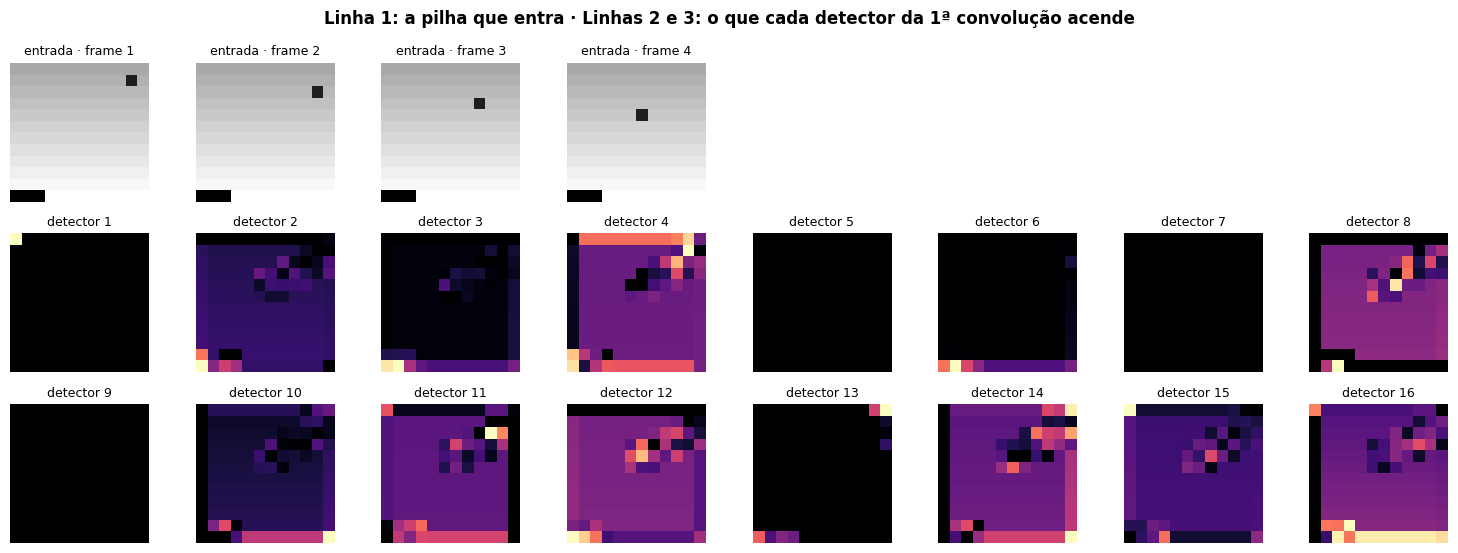

In [13]:
jogo, pilha = ChuvaDeMacas(seed=5).reset(), Pilha()
s = pilha.reiniciar(preparar(jogo.tela()))
for _ in range(4):
    jogo.passo(FICA)
    s = pilha.adicionar(preparar(jogo.tela()))
with torch.no_grad():
    mapas = rede.enxergar[1](rede.enxergar[0](torch.from_numpy(s)[None]))[0].numpy()   # conv1 + ReLU

fig = plt.figure(figsize=(15, 5.6))
for k in range(4):
    ax = fig.add_subplot(3, 8, k + 1)
    ax.imshow(s[k], cmap='gray'); ax.set_title(f'entrada · frame {k + 1}', fontsize=9); ax.axis('off')
for k in range(16):
    ax = fig.add_subplot(3, 8, 9 + k)
    ax.imshow(mapas[k], cmap='magma'); ax.set_title(f'detector {k + 1}', fontsize=9); ax.axis('off')
fig.suptitle('Linha 1: a pilha que entra · Linhas 2 e 3: o que cada detector da 1ª convolução acende', fontweight='bold')
plt.tight_layout(); plt.show()

**🔎 O que observar:** ninguém disse à rede o que é "maçã" ou "cesta". Mesmo assim, procure:
- detectores que acendem **só na cesta** (a barra no chão);
- detectores que acendem **na maçã**, alguns mostrando o **rastro** de várias posições (é aí que a direção do movimento entra na conta);
- detectores quase apagados: a rede não usa todos.

Esses padrões nasceram **sozinhos** do treino, só para aumentar os acertos. É isso que a CNN do DQN do Atari faz com a bola, a raquete e os tijolos.

---
## 9. 🏁 Avaliar direito (slide 131)

O slide 131 pede três cuidados: **testar sem explorar** (ε = 0), em **episódios só de avaliação**, e **comparar** com o acaso e com uma regra esperta. A regra esperta aqui é "**seguir a maçã**": mover a cesta para a coluna onde a maçã está **agora**.

> 🤔 **Palpite:** a regra "seguir a maçã" acerta mais ou menos que a rede treinada?

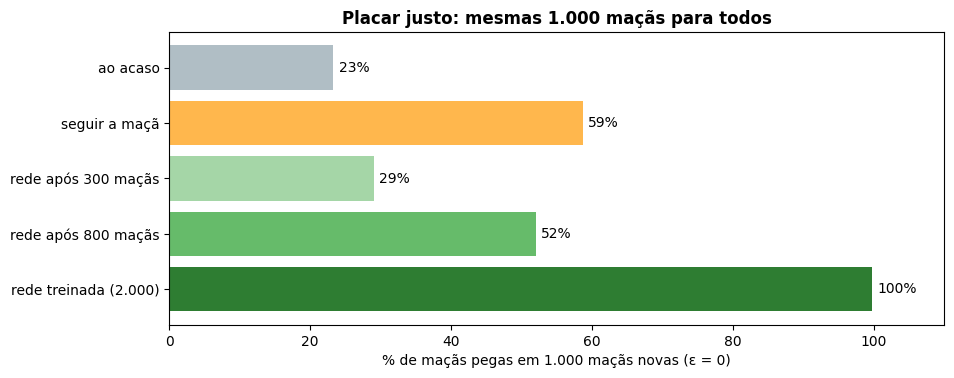

In [14]:
def avaliar(politica, n=1000, seed=999, n_frames=N_FRAMES):
    '''Joga n maçãs NOVAS (seed diferente do treino) e devolve a % de acertos.'''
    jogo, pilha, ok = ChuvaDeMacas(seed), Pilha(n_frames), 0
    for _ in range(n):
        s = pilha.reiniciar(preparar(jogo.reset().tela()))
        while True:
            r, fim = jogo.passo(politica(jogo, s))
            s = pilha.adicionar(preparar(jogo.tela()))
            if fim:
                ok += r > 0
                break
    return ok / n


def politica_da_rede(rede):
    def agir(jogo, s):
        with torch.no_grad():
            return int(rede(torch.from_numpy(s)[None]).argmax())   # ε = 0: só explota
    return agir


rng = np.random.default_rng(1)
concorrentes = {
    'ao acaso': lambda jogo, s: int(rng.integers(3)),
    'seguir a maçã': lambda jogo, s: 1 + int(np.sign(np.clip(jogo.ax, 1, L - 2) - jogo.cx)),
    'rede após 300 maçãs': politica_da_rede(fotos[300]),
    'rede após 800 maçãs': politica_da_rede(fotos[800]),
    'rede treinada (2.000)': politica_da_rede(rede),
}
placar = {nome: avaliar(p) for nome, p in concorrentes.items()}

fig, ax = plt.subplots(figsize=(10, 3.8))
cores = ['#B0BEC5', '#FFB74D', '#A5D6A7', '#66BB6A', '#2E7D32']
barras = ax.barh(list(placar), [v * 100 for v in placar.values()], color=cores)
ax.bar_label(barras, labels=[f'{v:.0%}' for v in placar.values()], padding=4)
ax.set_xlim(0, 110); ax.set_xlabel('% de maçãs pegas em 1.000 maçãs novas (ε = 0)'); ax.invert_yaxis()
ax.set_title('Placar justo: mesmas 1.000 maçãs para todos', fontweight='bold')
plt.show()

**🔎 O que observar**
- **"Seguir a maçã" acerta bem menos que a rede treinada:** a maçã é mais rápida que a cesta, então correr atrás dela não basta.
- **A rede treinada vai para onde a maçã VAI cair.** Ninguém programou essa estratégia: ela saiu do treino, a partir de pixels e de um +1 ou −1 no fim.
- **A evolução 300 → 800 → 2.000** mostra que a estratégia é construída aos poucos.

---
## 10. 🎯 Desafio: e se a rede visse só 1 frame? (slide 120)

Vamos treinar **a mesma rede**, com o mesmo número de maçãs, mas trocando a pilha de 4 frames por **1 frame** só.

> 🤔 **Palpite da dupla:** com 1 frame, a rede acerta... (a) quase 100%, como antes; (b) igual a "seguir a maçã"; (c) menos que "seguir a maçã"? Por quê?
>
> ⏱️ Mais 2 minutos de treino. Bom momento para discutir o palpite.

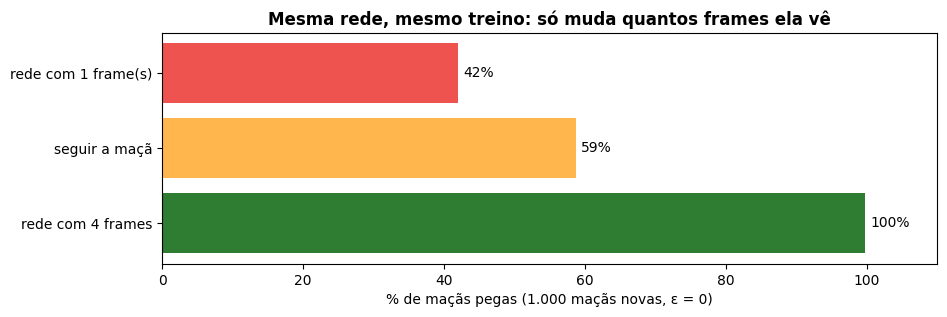

In [15]:
FRAMES_DESAFIO = 1   # 👈 experimente 1, 2 e 4

rede_desafio, acertos_desafio, _ = treinar(n_frames=FRAMES_DESAFIO, mostrar=False)
nota = avaliar(politica_da_rede(rede_desafio), n_frames=FRAMES_DESAFIO)

fig, ax = plt.subplots(figsize=(10, 3))
comparacao = {f'rede com {FRAMES_DESAFIO} frame(s)': nota, 'seguir a maçã': placar['seguir a maçã'],
              'rede com 4 frames': placar['rede treinada (2.000)']}
barras = ax.barh(list(comparacao), [v * 100 for v in comparacao.values()], color=['#EF5350', '#FFB74D', '#2E7D32'])
ax.bar_label(barras, labels=[f'{v:.0%}' for v in comparacao.values()], padding=4)
ax.set_xlim(0, 110); ax.set_xlabel('% de maçãs pegas (1.000 maçãs novas, ε = 0)'); ax.invert_yaxis()
ax.set_title(f'Mesma rede, mesmo treino: só muda quantos frames ela vê', fontweight='bold')
plt.show()

**🔎 O que observar** (na nossa execução; no seu Colab os números podem variar alguns pontos)
- **Com 1 frame, a rede acertou só 42%, menos até que a regra "seguir a maçã" (59%).** A resposta do palpite é a (c).
- **Por quê?** Sem saber a direção, a rede não consegue prever onde a maçã vai cair. E ela nem consegue "seguir" bem, porque só aprendeu a partir de fotos soltas, em que a mesma imagem às vezes acabou em +1 e às vezes em −1.
- **Com 4 frames, a mesma rede chega a 100%.** O algoritmo, a rede e o treino são idênticos: **só o estado mudou**.
- **Experimente 2 frames:** já basta para ver a direção? (Dica: a velocidade é a diferença entre duas posições.)

**Para fixar (slide 120):** 1 frame é uma **foto**: mostra onde a maçã está. 4 frames são um **vídeo**: mostram para onde ela vai e com que velocidade. Nenhum algoritmo, por melhor que seja, decide bem com um estado que esconde o que importa.

---
## 11. 🎯 Mão na massa: qual ideia do DQN mais muda a curva? (slides 123 a 125)

O slide 125 pergunta: **qual das 3 ideias mais muda a curva de aprendizado?** Vamos tirar uma de cada vez, mantendo todo o resto igual.

| Teste | O que muda | Slide |
|---|---|---|
| **Sem replay** | o caderno guarda só **1 linha**: cada atualização usa só a última jogada | 123 |
| **Rede-alvo a cada 1 passo** | o gabarito é atualizado o tempo todo, ou seja, praticamente **sem rede-alvo** | 124 |

> 🤔 **Palpite da dupla (anote!):** qual dos dois atrapalha mais? Algum deles impede a rede de aprender?
>
> ⏱️ Mais cerca de 2 minutos e meio de treino.

✔ sem replay (caderno de 1 linha): 51 s


✔ rede-alvo a cada 1 passo: 112 s


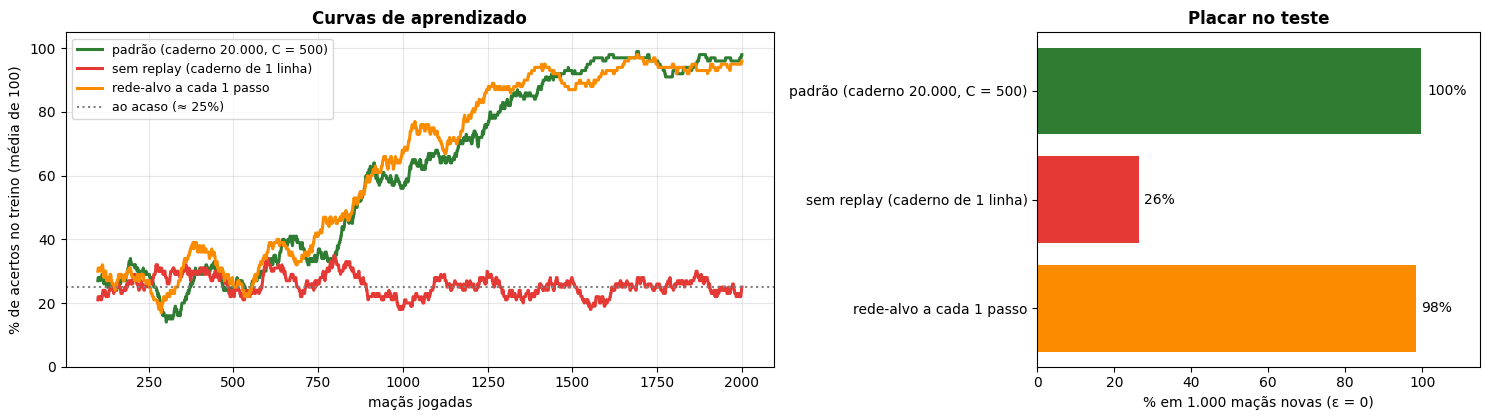

In [16]:
testes = {
    'sem replay (caderno de 1 linha)': dict(capacidade=1),
    'rede-alvo a cada 1 passo': dict(C=1),   # 👈 experimente também C=2000
}
resultados = {'padrão (caderno 20.000, C = 500)': (acertos, placar['rede treinada (2.000)'])}
for nome, kw in testes.items():
    inicio = time.time()
    rede_teste, acertos_teste, _ = treinar(mostrar=False, **kw)
    resultados[nome] = (acertos_teste, avaliar(politica_da_rede(rede_teste)))
    print(f'✔ {nome}: {time.time() - inicio:.0f} s')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={'width_ratios': [1.6, 1]})
cores = ['#2E7D32', '#E53935', '#FB8C00']
for (nome, (hist, nota)), cor in zip(resultados.items(), cores):
    axes[0].plot(range(100, len(hist) + 1), np.convolve(hist, np.ones(100) / 100, mode='valid') * 100,
                 color=cor, lw=2.2, label=nome)
axes[0].axhline(25, color='gray', ls=':', label='ao acaso (≈ 25%)')
axes[0].set_xlabel('maçãs jogadas'); axes[0].set_ylabel('% de acertos no treino (média de 100)')
axes[0].set_ylim(0, 105); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=9)
axes[0].set_title('Curvas de aprendizado', fontweight='bold')
notas = {nome: nota for nome, (_, nota) in resultados.items()}
barras = axes[1].barh(list(notas), [v * 100 for v in notas.values()], color=cores)
axes[1].bar_label(barras, labels=[f'{v:.0%}' for v in notas.values()], padding=4)
axes[1].set_xlim(0, 115); axes[1].invert_yaxis(); axes[1].set_xlabel('% em 1.000 maçãs novas (ε = 0)')
axes[1].set_title('Placar no teste', fontweight='bold')
plt.tight_layout(); plt.show()

**🔎 O que observar** (na nossa execução; no seu Colab os números podem variar alguns pontos)
- **Sem replay, a rede não aprende nada:** a curva vermelha fica colada nos 25% do acaso o treino inteiro, e no teste ela acerta 26%. Cada atualização usa só a última jogada, e jogadas seguidas são quase iguais (slide 123: "passos seguidos se parecem"). Pior: o +1 ou −1 só aparece no último passo de cada maçã, e a rede o "esquece" nas atualizações seguintes.
- **Sem rede-alvo (atualizada a cada passo), a rede aprende quase igual:** 98% contra 100%. Num jogo pequeno, o "alvo que foge" não chega a atrapalhar.
- **Isso não prova que a rede-alvo é inútil.** Ela foi criada para problemas como o Atari (milhões de passos, telas de 84 × 84), onde sem ela o treino oscila ou diverge (Mnih et al., 2015). Um resultado num problema pequeno não se generaliza sozinho para um grande (slide 131).
- **Resposta do slide 125, neste jogo:** a ideia que mais muda a curva é o **replay**.

**📝 Entrega da dupla:** o gráfico acima e uma frase respondendo ao slide 125: qual ideia mais mudou a curva, e por quê?

---
## 🏁 Resumo: onde cada slide apareceu

| Slide | Ideia | Onde você viu |
|---|---|---|
| 118 | a tabela não cabe quando o estado é uma tela | seção 4 (256⁵⁷⁶ linhas) |
| 119 | mesma conta do Q-Learning, outra memória | `passo_de_treino`: o alvo r + γ · max Q |
| 120 | cinza, reduzir, empilhar 4 frames | seções 2, 3 e 10 |
| 121 | enxergar → combinar → pontuar | seções 4, 7 e 8 |
| 122–123 | o caderno (replay): sem ele, a rede não aprende | `Caderno` e seção 11 |
| 124 | o gabarito congelado (rede-alvo) e a conta do erro | seção 5 e seção 11 |
| 125 | Q-Learning + 3 ideias: qual pesa mais? | seção 11 |
| 131 | avaliar com método | seções 6 e 9 |

## 💭 Para pensar (em dupla)

1. **Slide 120:** em que jogo a **cor** mudaria a decisão? E, no Quantum Finance, o que seriam os "4 frames"? (Dica: uma janela com os preços dos últimos dias.)
2. **Slide 121:** se o jogo ganhasse a ação PULAR, o que mudaria na rede? E no resto do código?
3. **Você × rede:** quantas maçãs você pegou na seção 1? Você usou a mesma estratégia que a rede descobriu?
4. **Recompensa:** e se pegar a maçã valesse +1 e deixar cair valesse 0, em vez de −1? O que mudaria no treino?

**Próximo passo:** o mesmo DQN, em escala de verdade, jogando **Atari Breakout** (slide 127, `exemplo_DQN_Breakout.ipynb`).